# 01 · Real-data exploratory analysis

**Question:** which discharge-available characteristics are associated with recorded 30-day readmission?

The source is the unchanged UCI ZIP. The prediction time is discharge. Model-guiding EDA uses **training patients only**; the validation set sets operating points and the test set remains untouched until selection is frozen. These are retrospective associations, not causal treatment effects.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "hospital_readmission").is_dir())
def report(name):
    return json.loads((ROOT / "reports" / name).read_text())
def figure(name):
    display(Image(filename=str(ROOT / "figures" / name)))
from hospital_readmission.data import load_diabetes
from hospital_readmission.cohort import make_cohort
from hospital_readmission.config import ExperimentConfig
from hospital_readmission.splitting import split_patients
dataset = load_diabetes()
cohort, cohort_audit = make_cohort(dataset)
splits, split_audit = split_patients(cohort, ExperimentConfig())
training = cohort.iloc[splits["train"]]
print("Real ZIP loaded offline:", dataset.data.shape, "eligible:", cohort.shape)


Real ZIP loaded offline: (101766, 50) eligible: (99319, 50)


In [2]:
display(pd.DataFrame(cohort_audit["exclusions"]))
display(pd.DataFrame({k:split_audit[k] for k in ["train","validation","test"]}).T)

,code,reason,rows
0,9,Admitted as an inpatient to this hospital: not...,21
1,11,Expired,1642
2,12,Still a patient: not a completed discharge,3
3,13,Hospice at home,399
4,14,Hospice in a medical facility,372
5,19,Expired at home,8
6,20,Expired in a medical facility,2
7,21,"Expired, location unknown",0


,encounters,patients,positives,prevalence,encounter_id_sha256
train,63566,44880,7234,0.113803,8e50d29b60aa8b51185d0837ad8616f3b051e33538370e...
validation,15892,11137,1809,0.113831,5925f24fcd3df132486c19643ff405f21358d79d3acbd4...
test,19861,13963,2260,0.113791,5f8bbc8dbb708ea009d50a28a682a949c8117a7f1331a2...


## Data quality and missingness
Question marks become missing values. Literal `None` in the two laboratory columns means **not measured** and is retained. Missingness may encode clinical decision-making; imputation does not make it missing at random. No patient-level records or identifiers are displayed.

In [3]:
display(pd.read_csv(ROOT / "reports/training_data_dictionary.csv"))
display(pd.read_csv(ROOT / "reports/numeric_descriptive_statistics.csv", index_col=0))
display(pd.read_csv(ROOT / "reports/categorical_statistics.csv"))

,column,dtype,unique_values,missing
0,encounter_id,string,63566,0
1,patient_nbr,string,44880,0
2,race,string,5,1473
3,gender,string,3,0
4,age,string,10,0
5,weight,string,8,61548
6,admission_type_id,int64,8,0
7,discharge_disposition_id,int64,19,0
8,admission_source_id,int64,15,0
9,time_in_hospital,int64,14,0


,count,mean,std,min,25%,50%,75%,95%,99%,max
time_in_hospital,63566.0,4.372982,2.960125,1.0,2.0,4.0,6.0,11.0,13.0,14.0
num_lab_procedures,63566.0,42.870119,19.592683,1.0,31.0,44.0,57.0,73.0,84.0,132.0
num_procedures,63566.0,1.343234,1.705592,0.0,0.0,1.0,2.0,5.0,6.0,6.0
num_medications,63566.0,15.965091,8.099615,1.0,10.0,15.0,20.0,31.0,43.0,81.0
number_outpatient,63566.0,0.367303,1.235874,0.0,0.0,0.0,0.0,2.0,5.0,42.0
number_emergency,63566.0,0.198282,0.990880,0.0,0.0,0.0,0.0,1.0,3.0,76.0
number_inpatient,63566.0,0.619341,1.224377,0.0,0.0,0.0,1.0,3.0,6.0,19.0
number_diagnoses,63566.0,7.394393,1.944800,1.0,6.0,8.0,9.0,9.0,9.0,16.0
age_midpoint,63566.0,65.619199,15.990159,5.0,55.0,65.0,75.0,85.0,95.0,95.0
prior_visit_total,63566.0,1.184926,2.267605,0.0,0.0,0.0,2.0,5.0,10.0,80.0


,column,unique,most_frequent_category,most_frequent_count
0,race,5,Caucasian,47517
1,gender,3,Female,34091
2,age,10,[70-80),16078
3,weight,8,NaN,61548
4,payer_code,17,NaN,25180
5,medical_specialty,70,NaN,31058
6,diag_1,670,414,4218
7,diag_2,693,276,4245
8,diag_3,733,250,7414
9,max_glu_serum,4,NaN,60274


scope                                            training partition only
rows                                                               63566
patients                                                           44880
missing_values         {'weight': 61548, 'medical_specialty': 31058, ...
lab_not_measured            {'max_glu_serum': 60274, 'A1Cresult': 52816}
target_counts                   {'NO': 33725, '>30': 22607, '<30': 7234}
constant_predictors    [acetohexamide, examide, citoglipton, glimepir...
unknown_gender_rows                                                    2
dtype: object

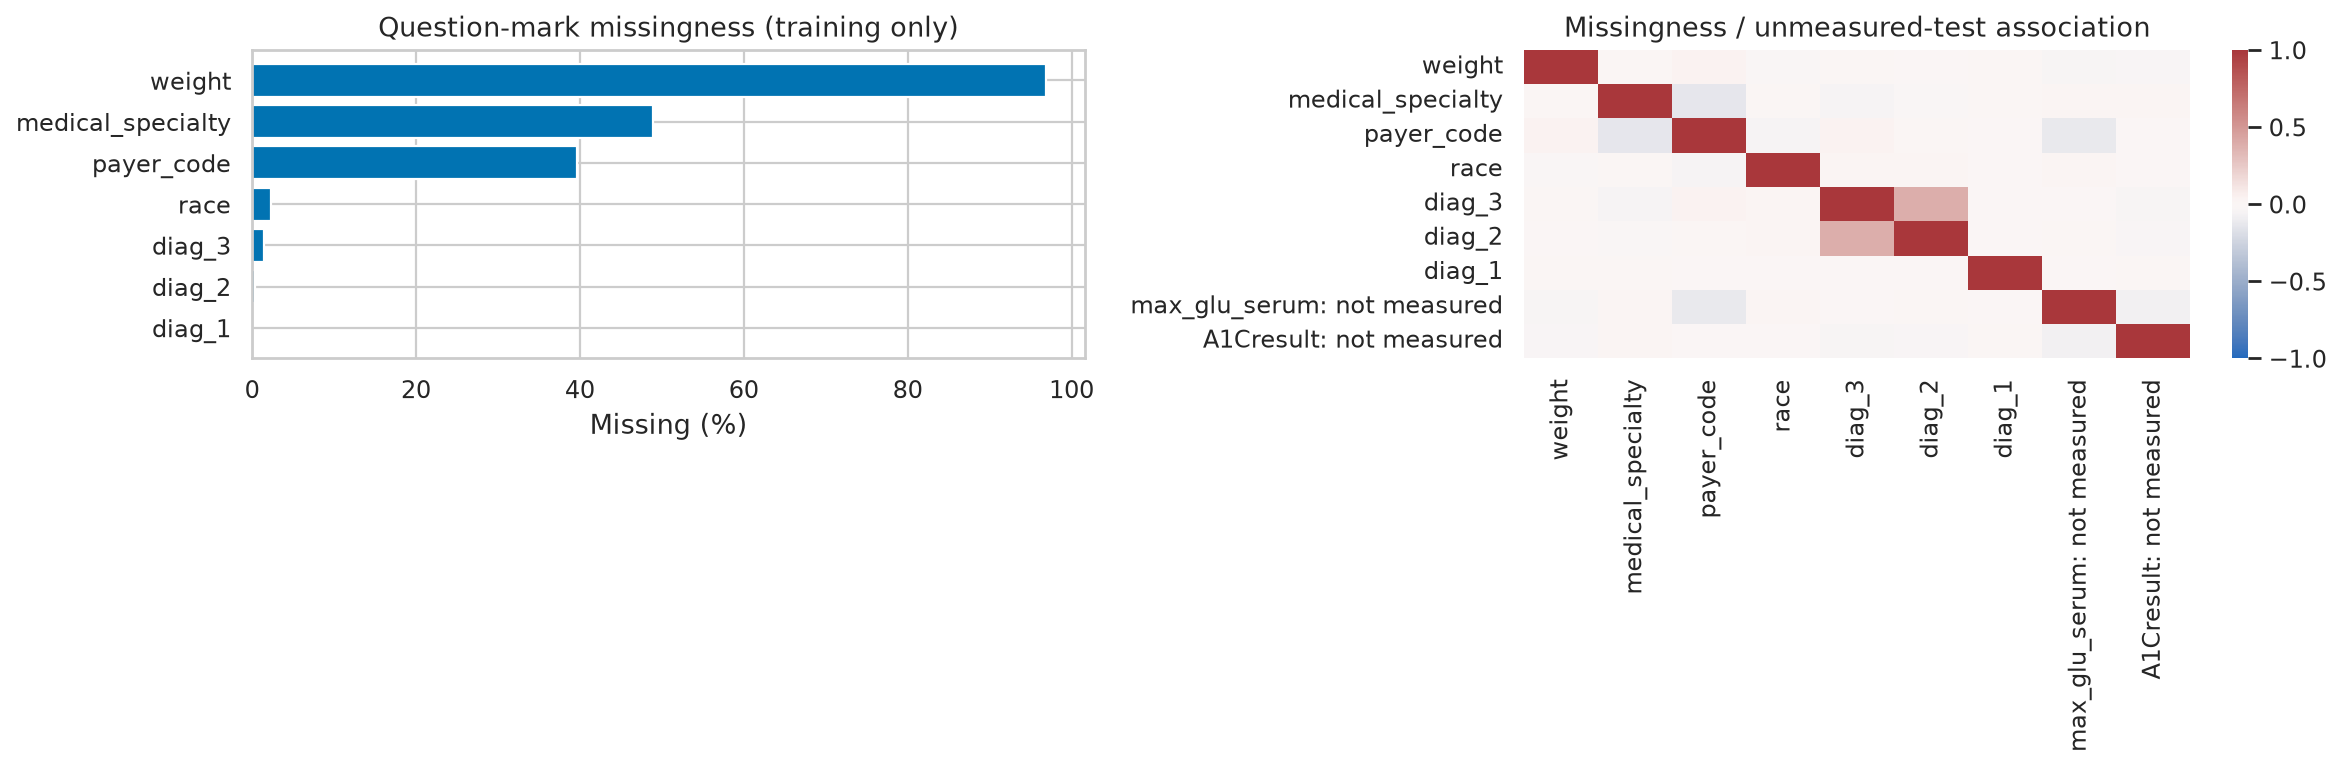

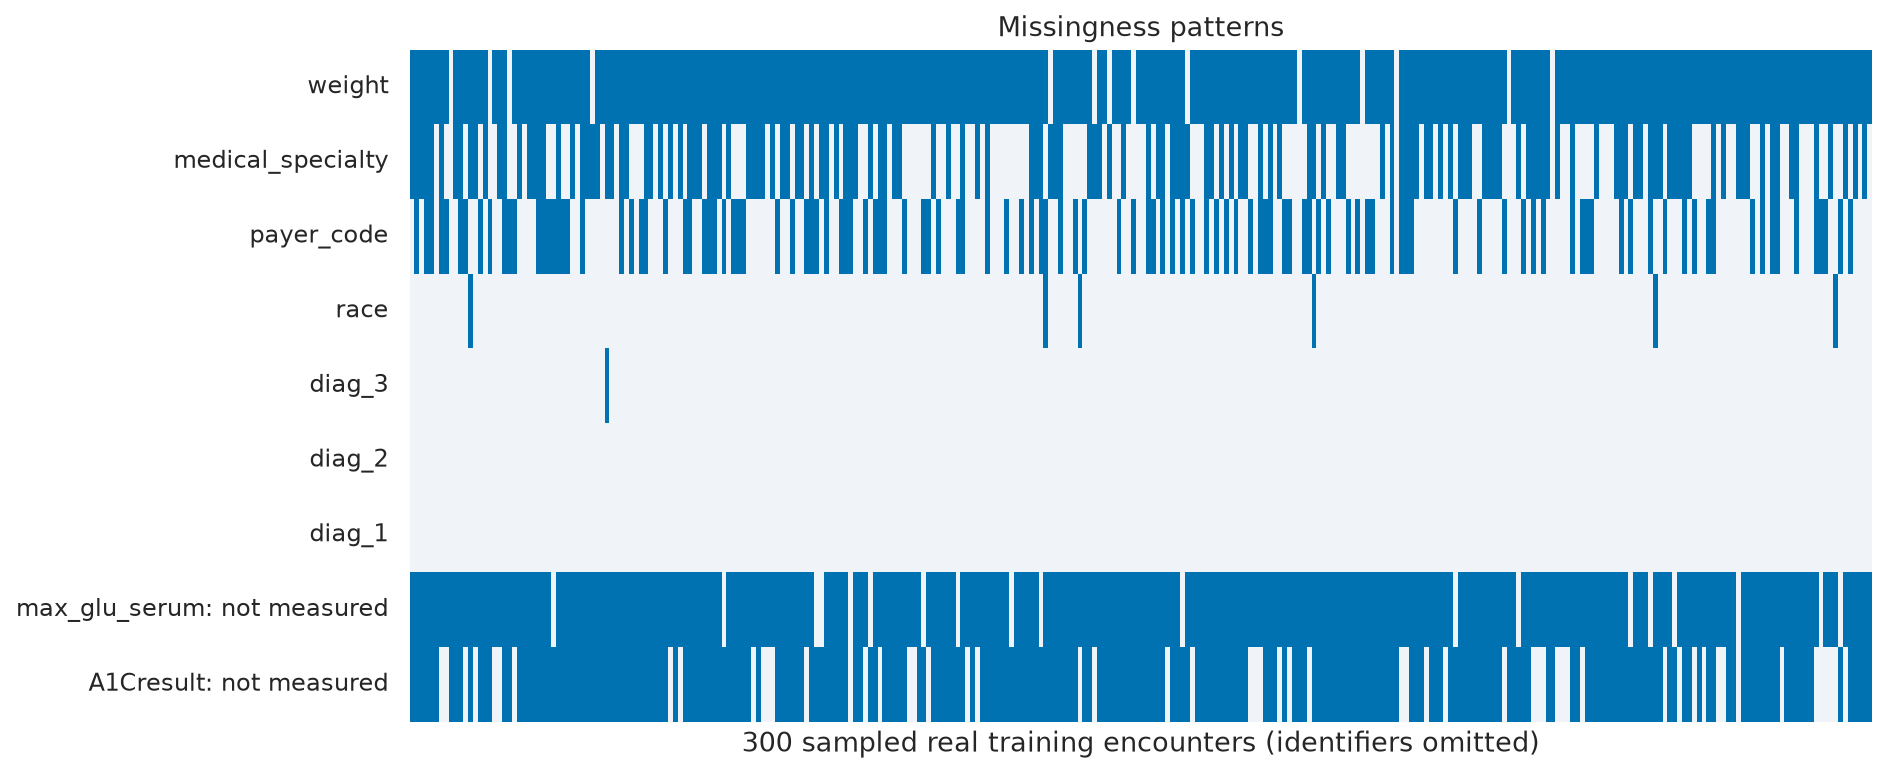

In [4]:
display(pd.Series(report("training_data_quality.json")))
figure("eda_missingness.png")
figure("eda_missingness_patterns.png")

## Class imbalance, demographics and admission characteristics
Readmission rates use encounter denominators. Wilson intervals in these descriptive plots are unadjusted for repeated patients. Small groups have considerable uncertainty; they do not establish group-specific causal effects.

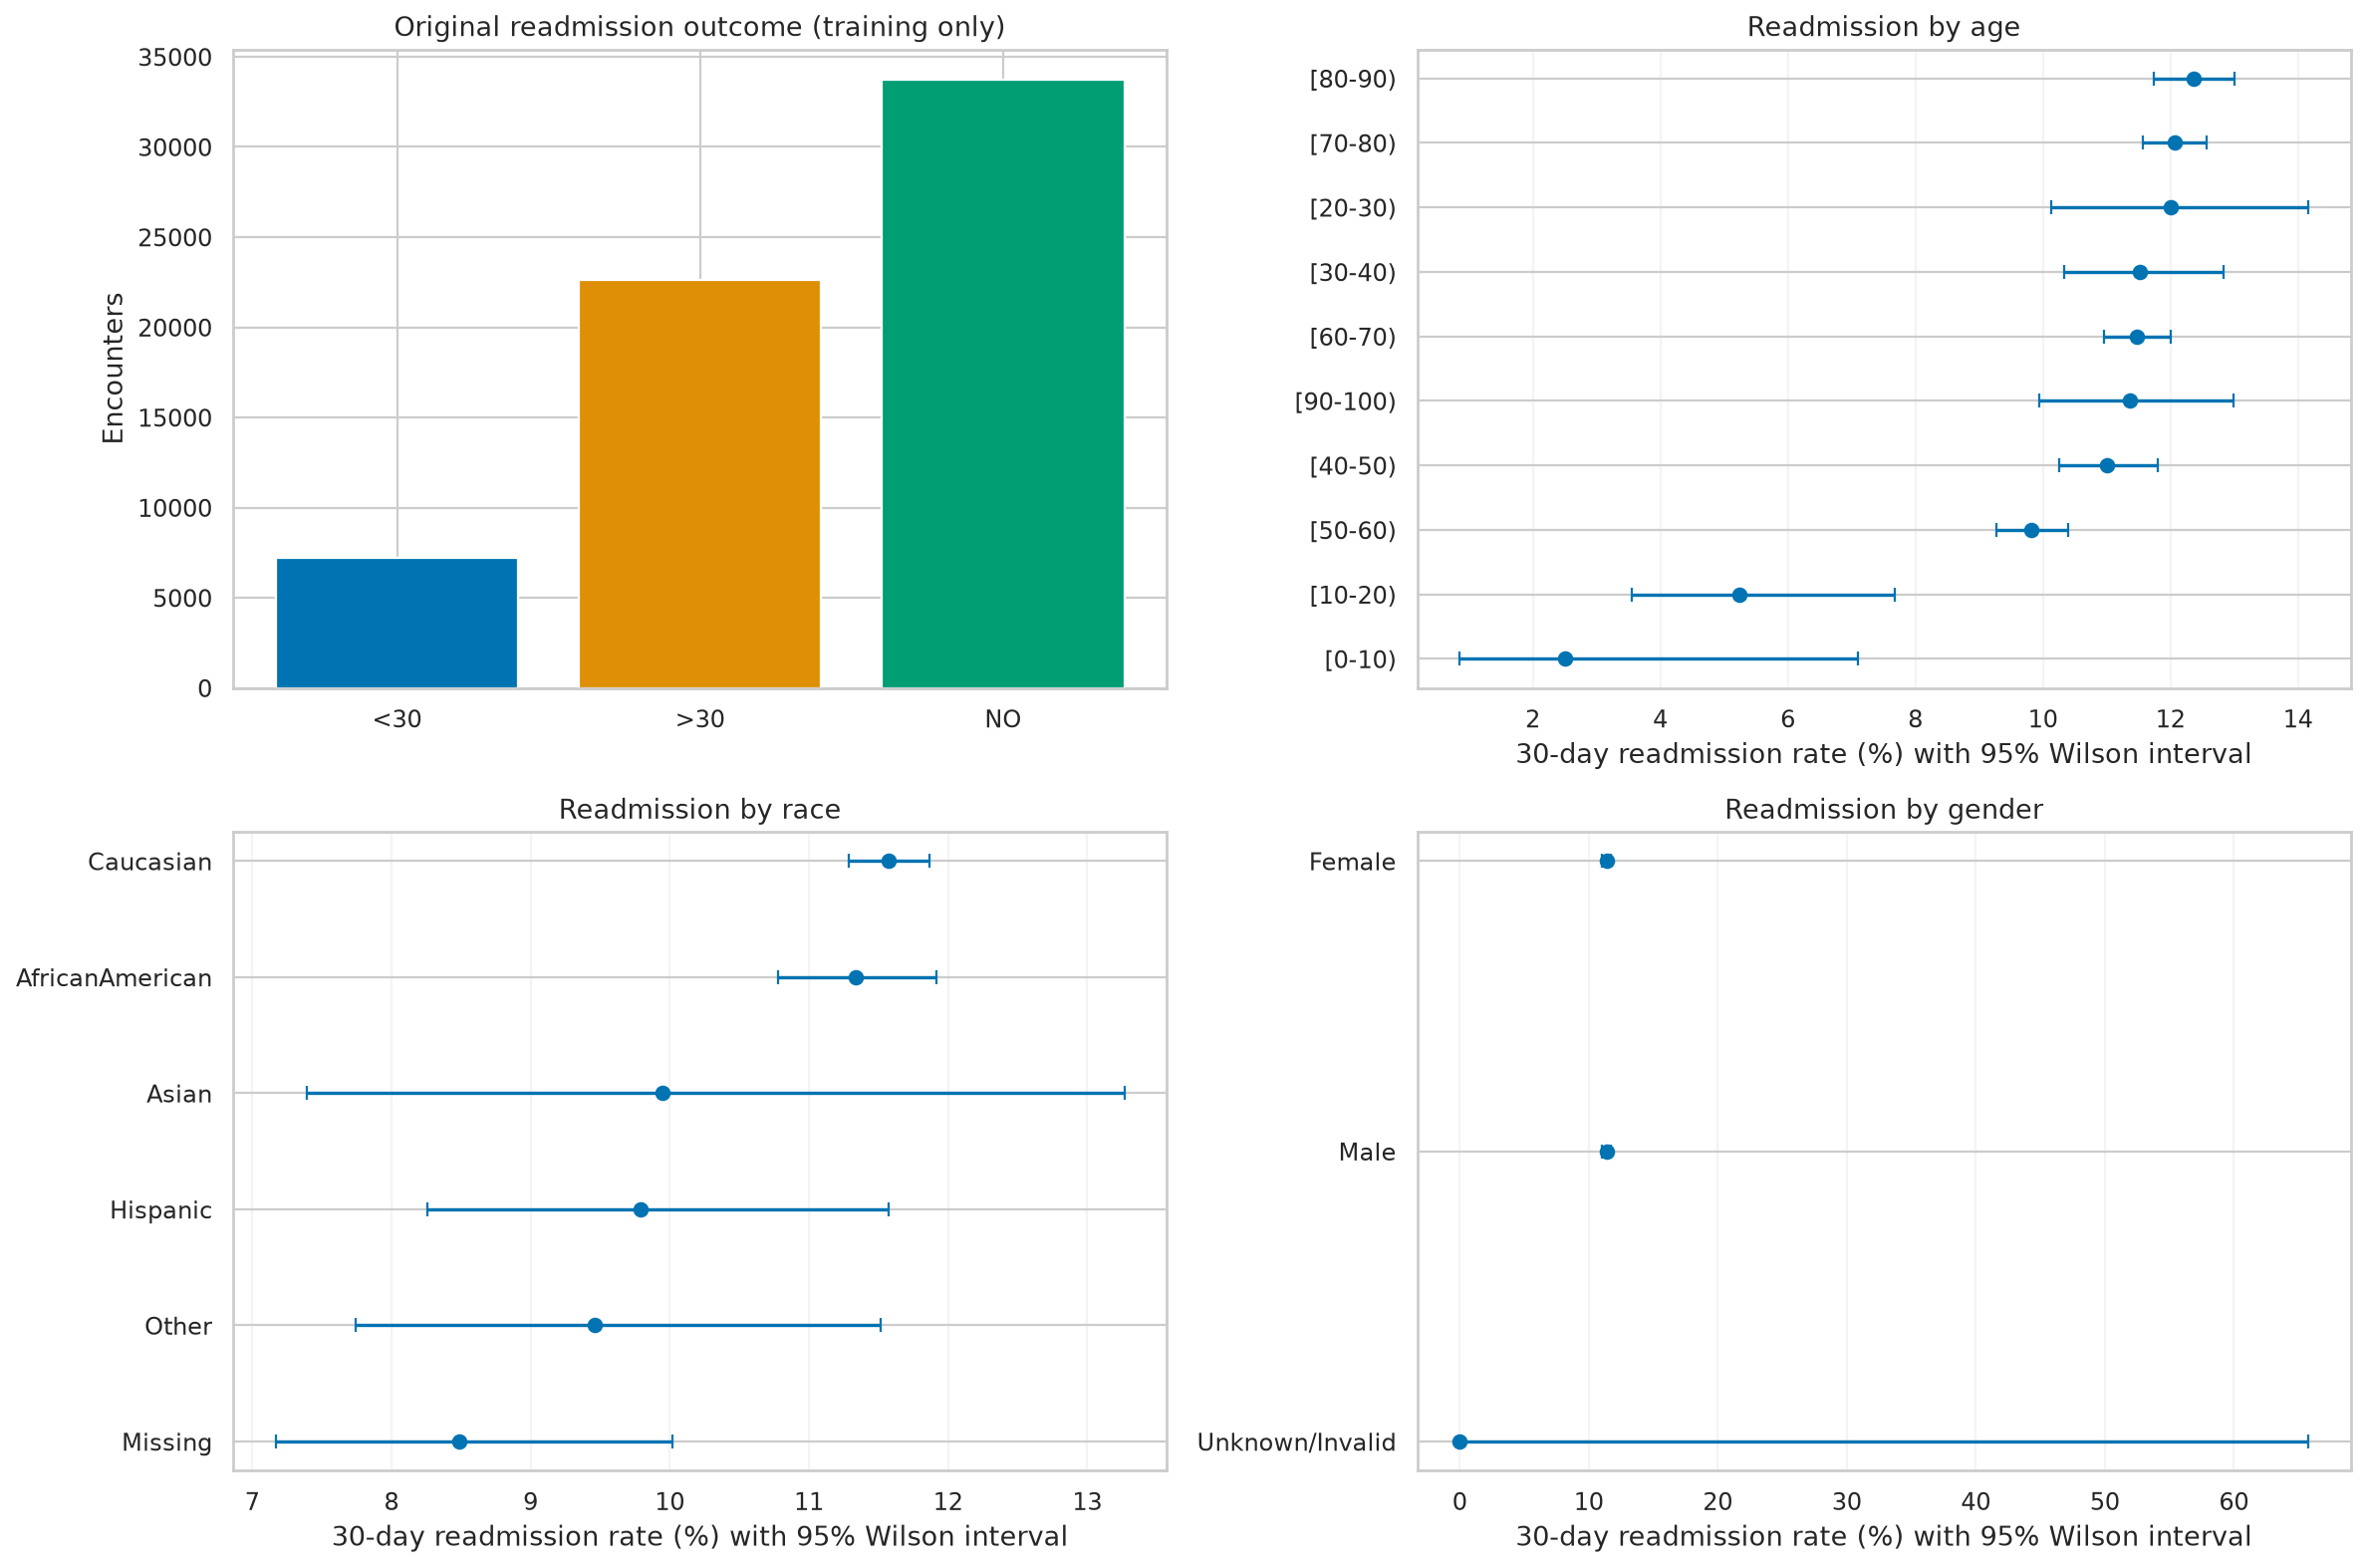

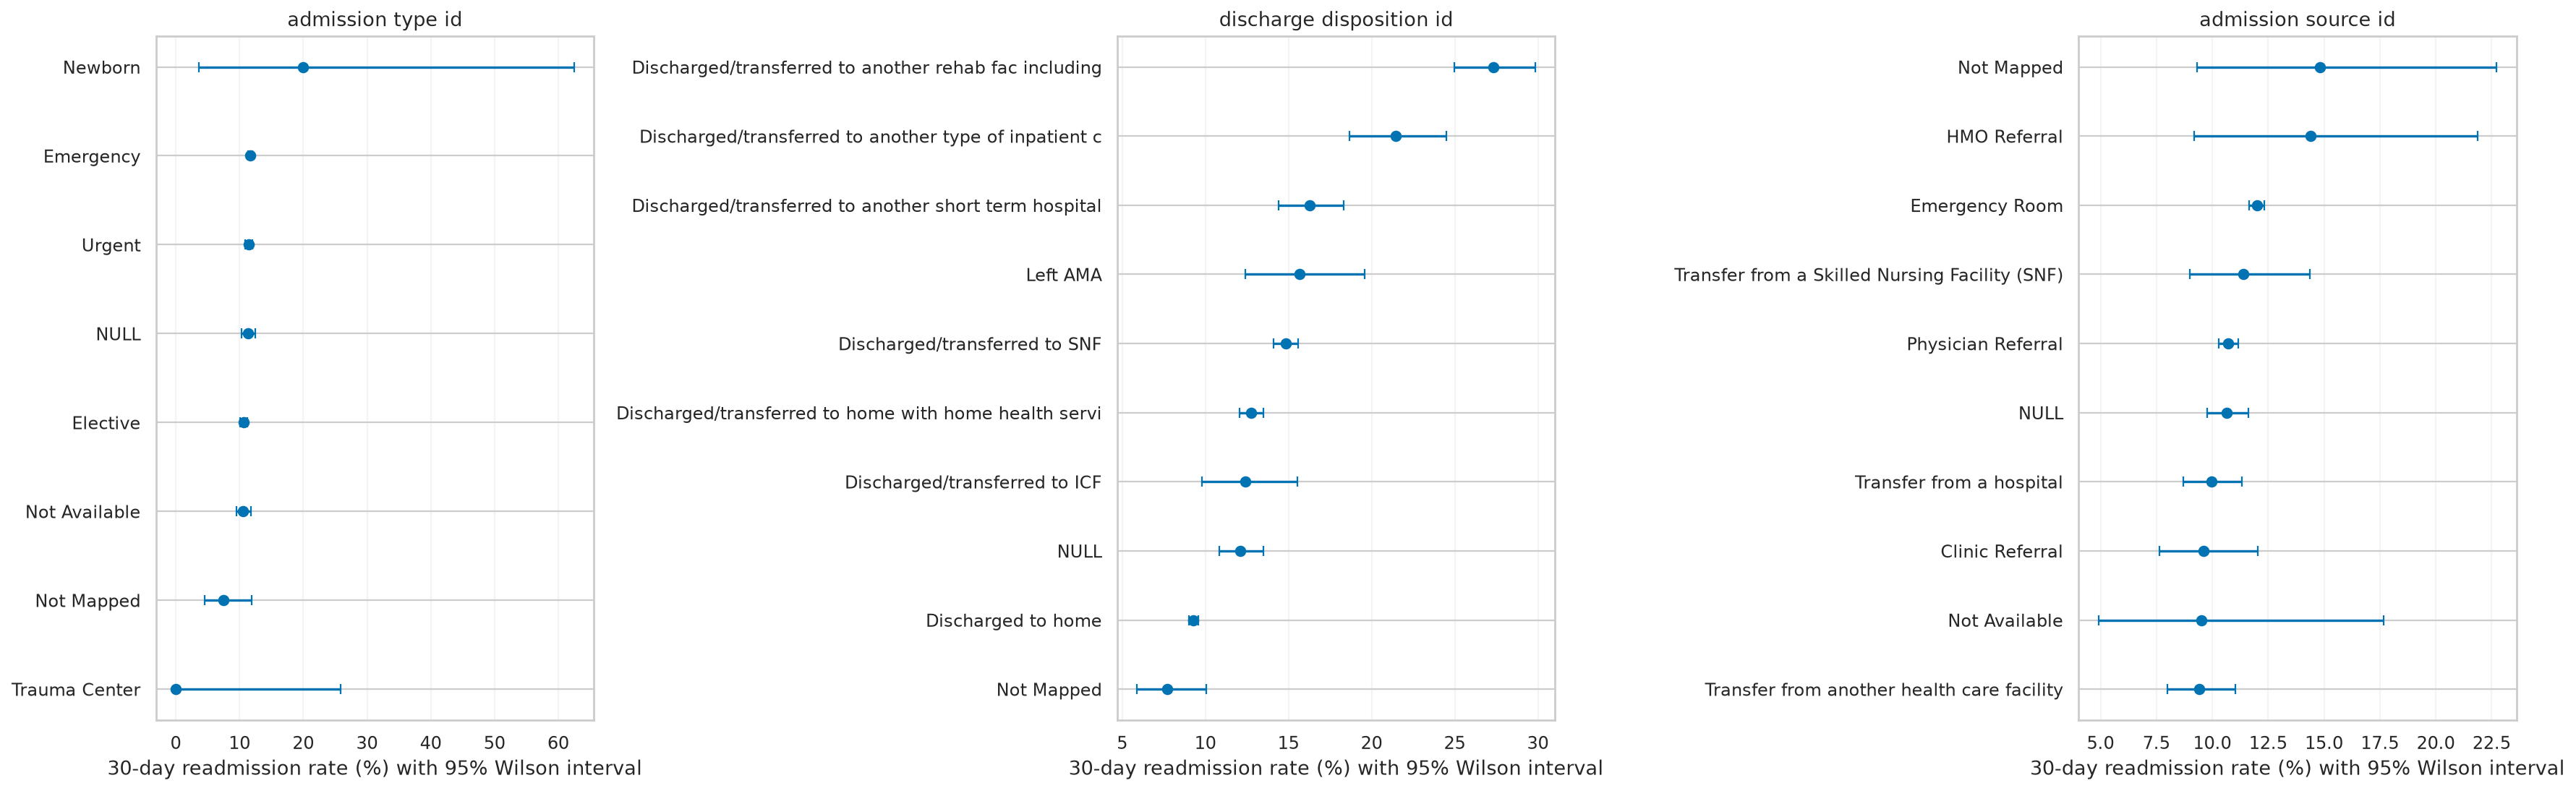

In [5]:
figure("eda_demographics.png")
figure("eda_admissions.png")

## Previous utilisation, diagnoses and clinical predictors
Prior visit counts are supplied by the source; no future encounter history is constructed. ICD-9 codes are grouped using prespecified rules. Diagnosis categories, insulin changes and test ordering may reflect severity and care processes rather than treatment effects.

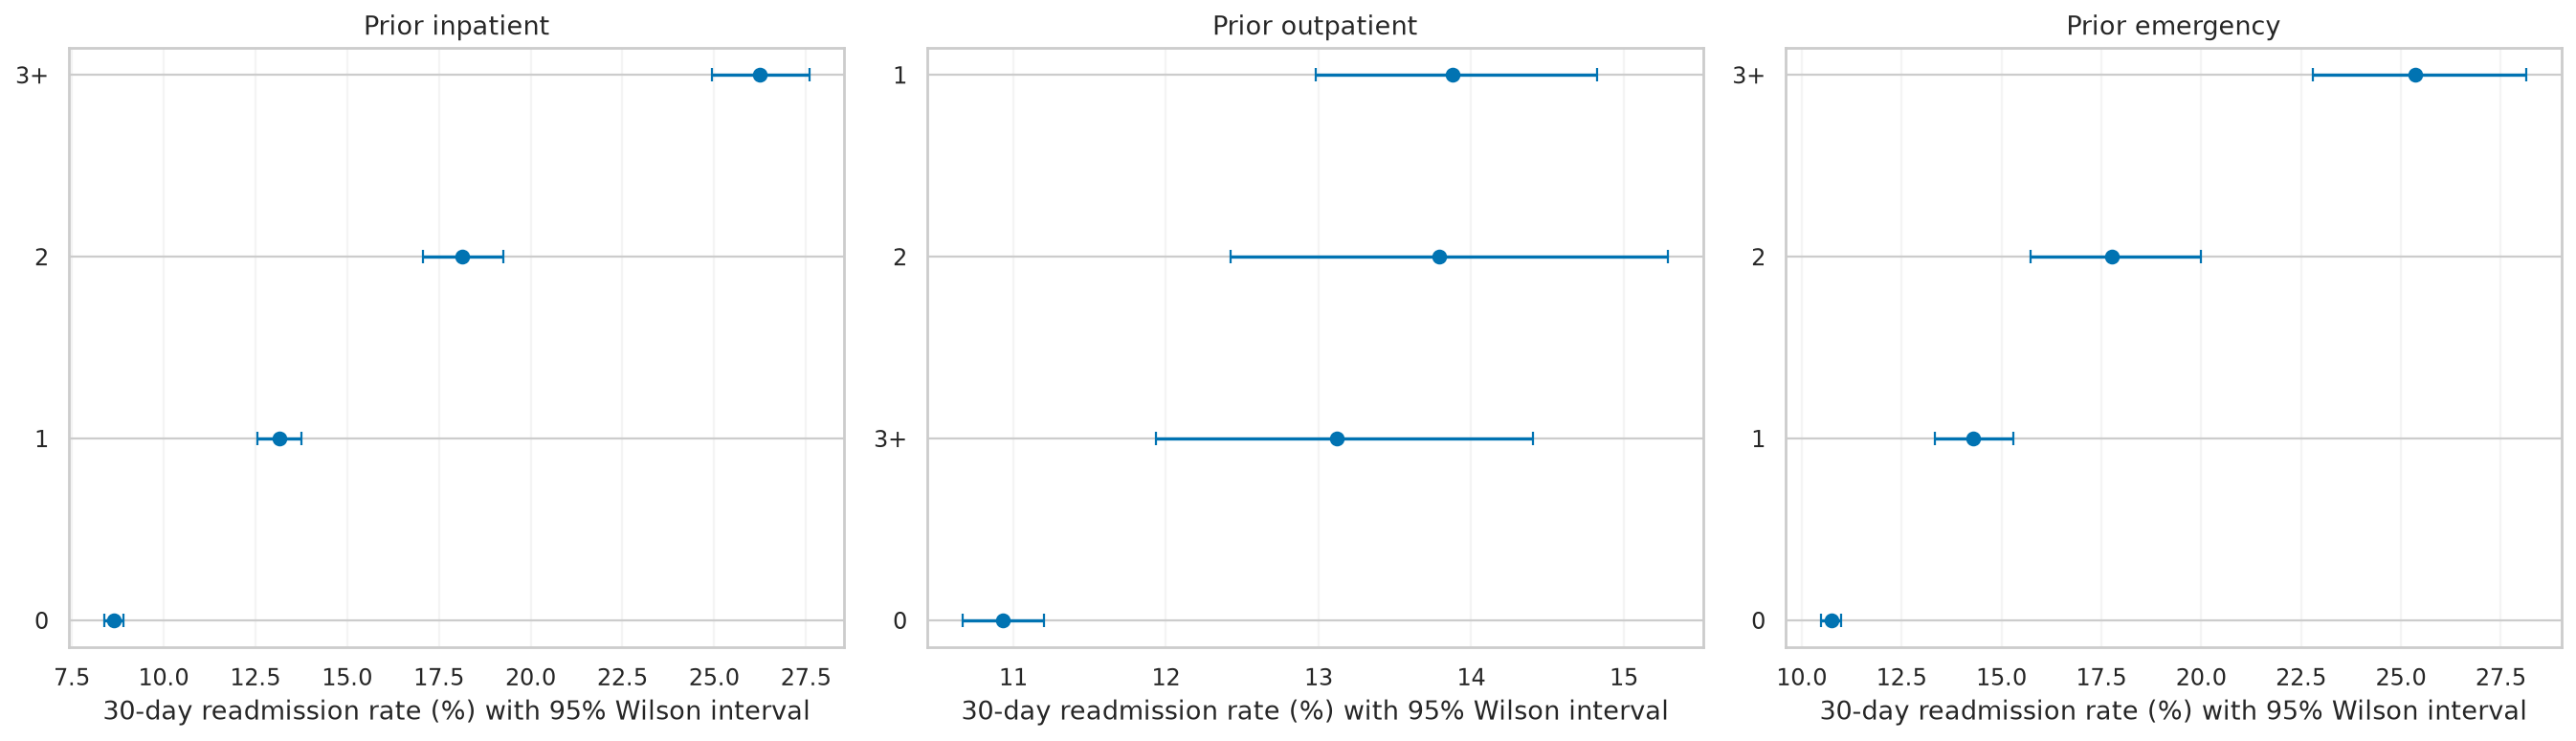

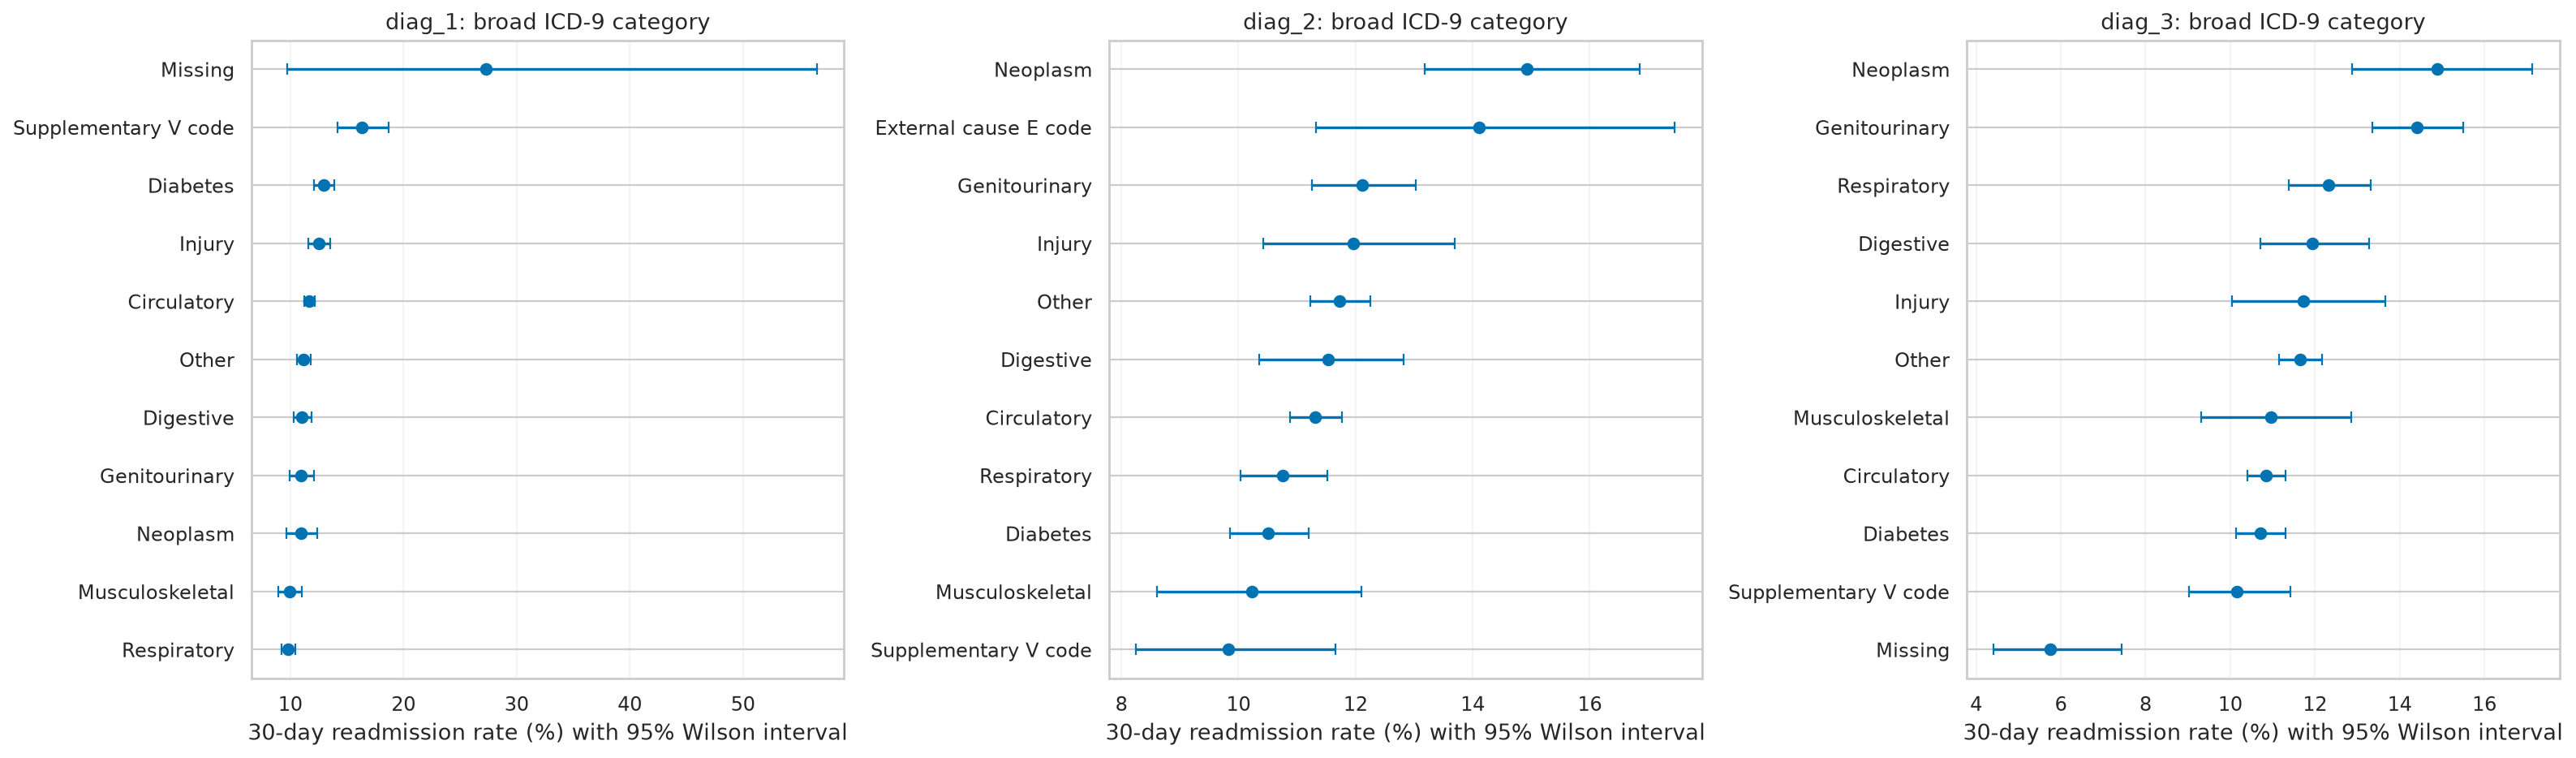

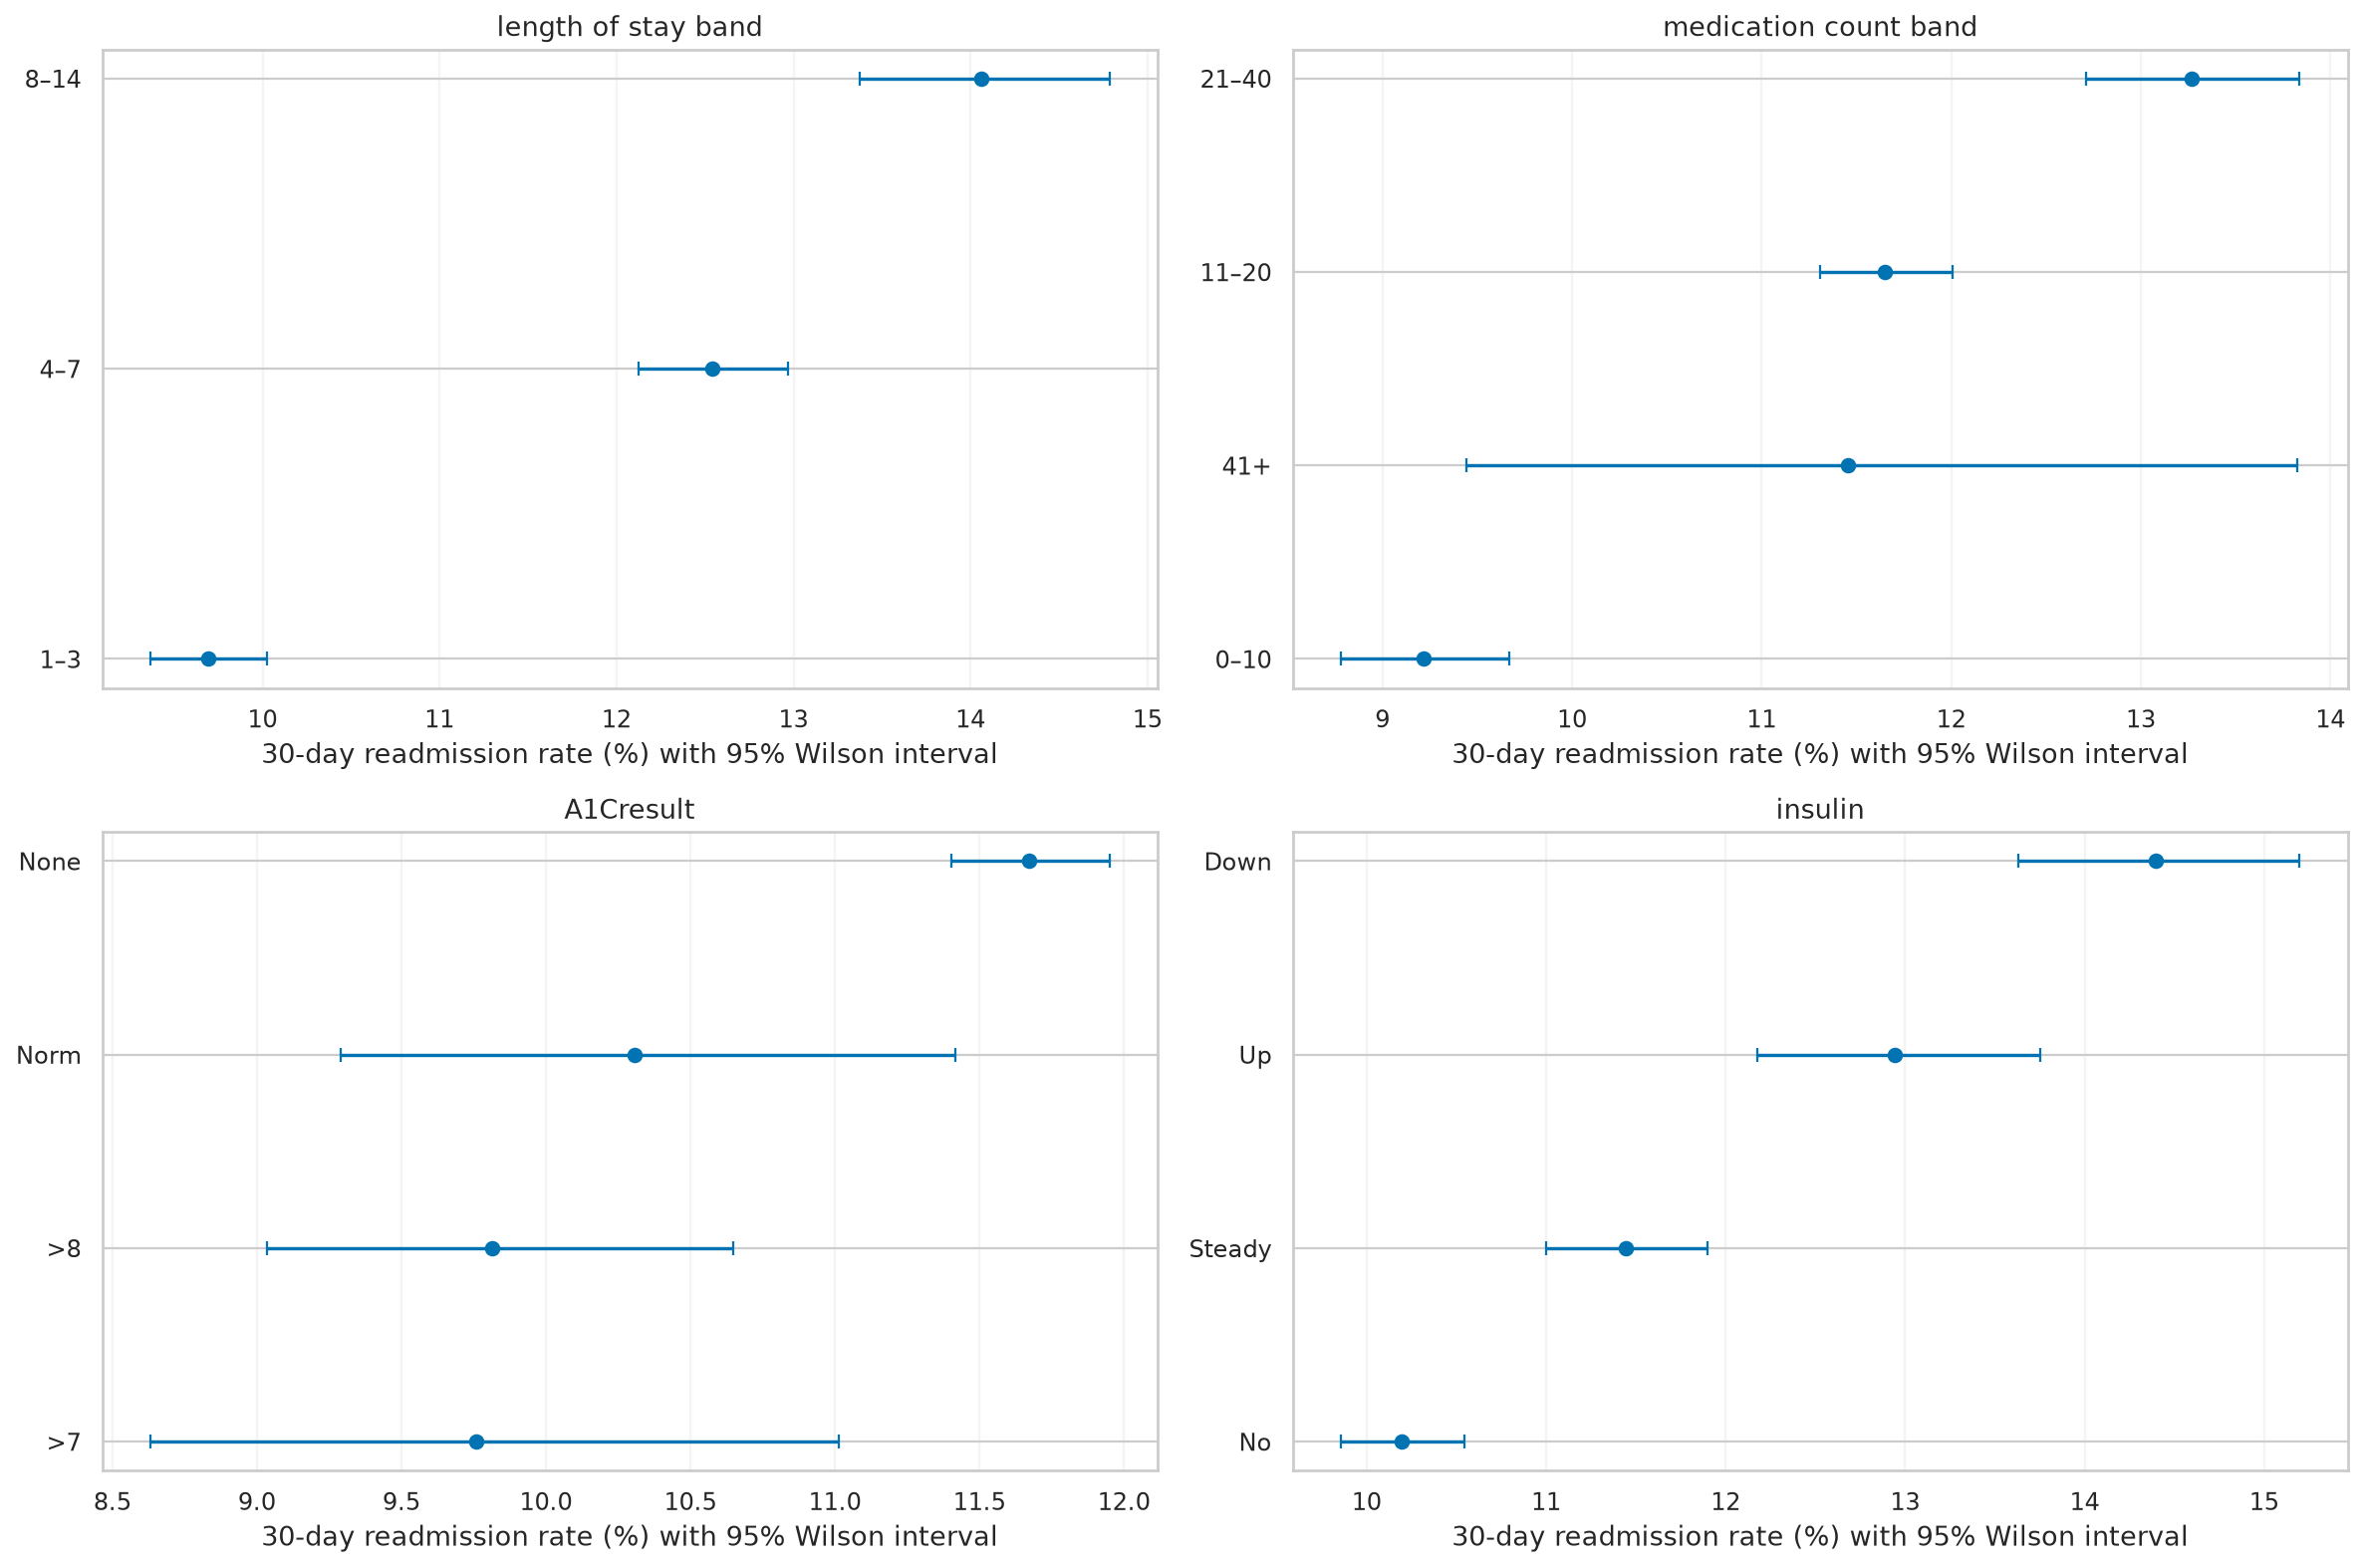

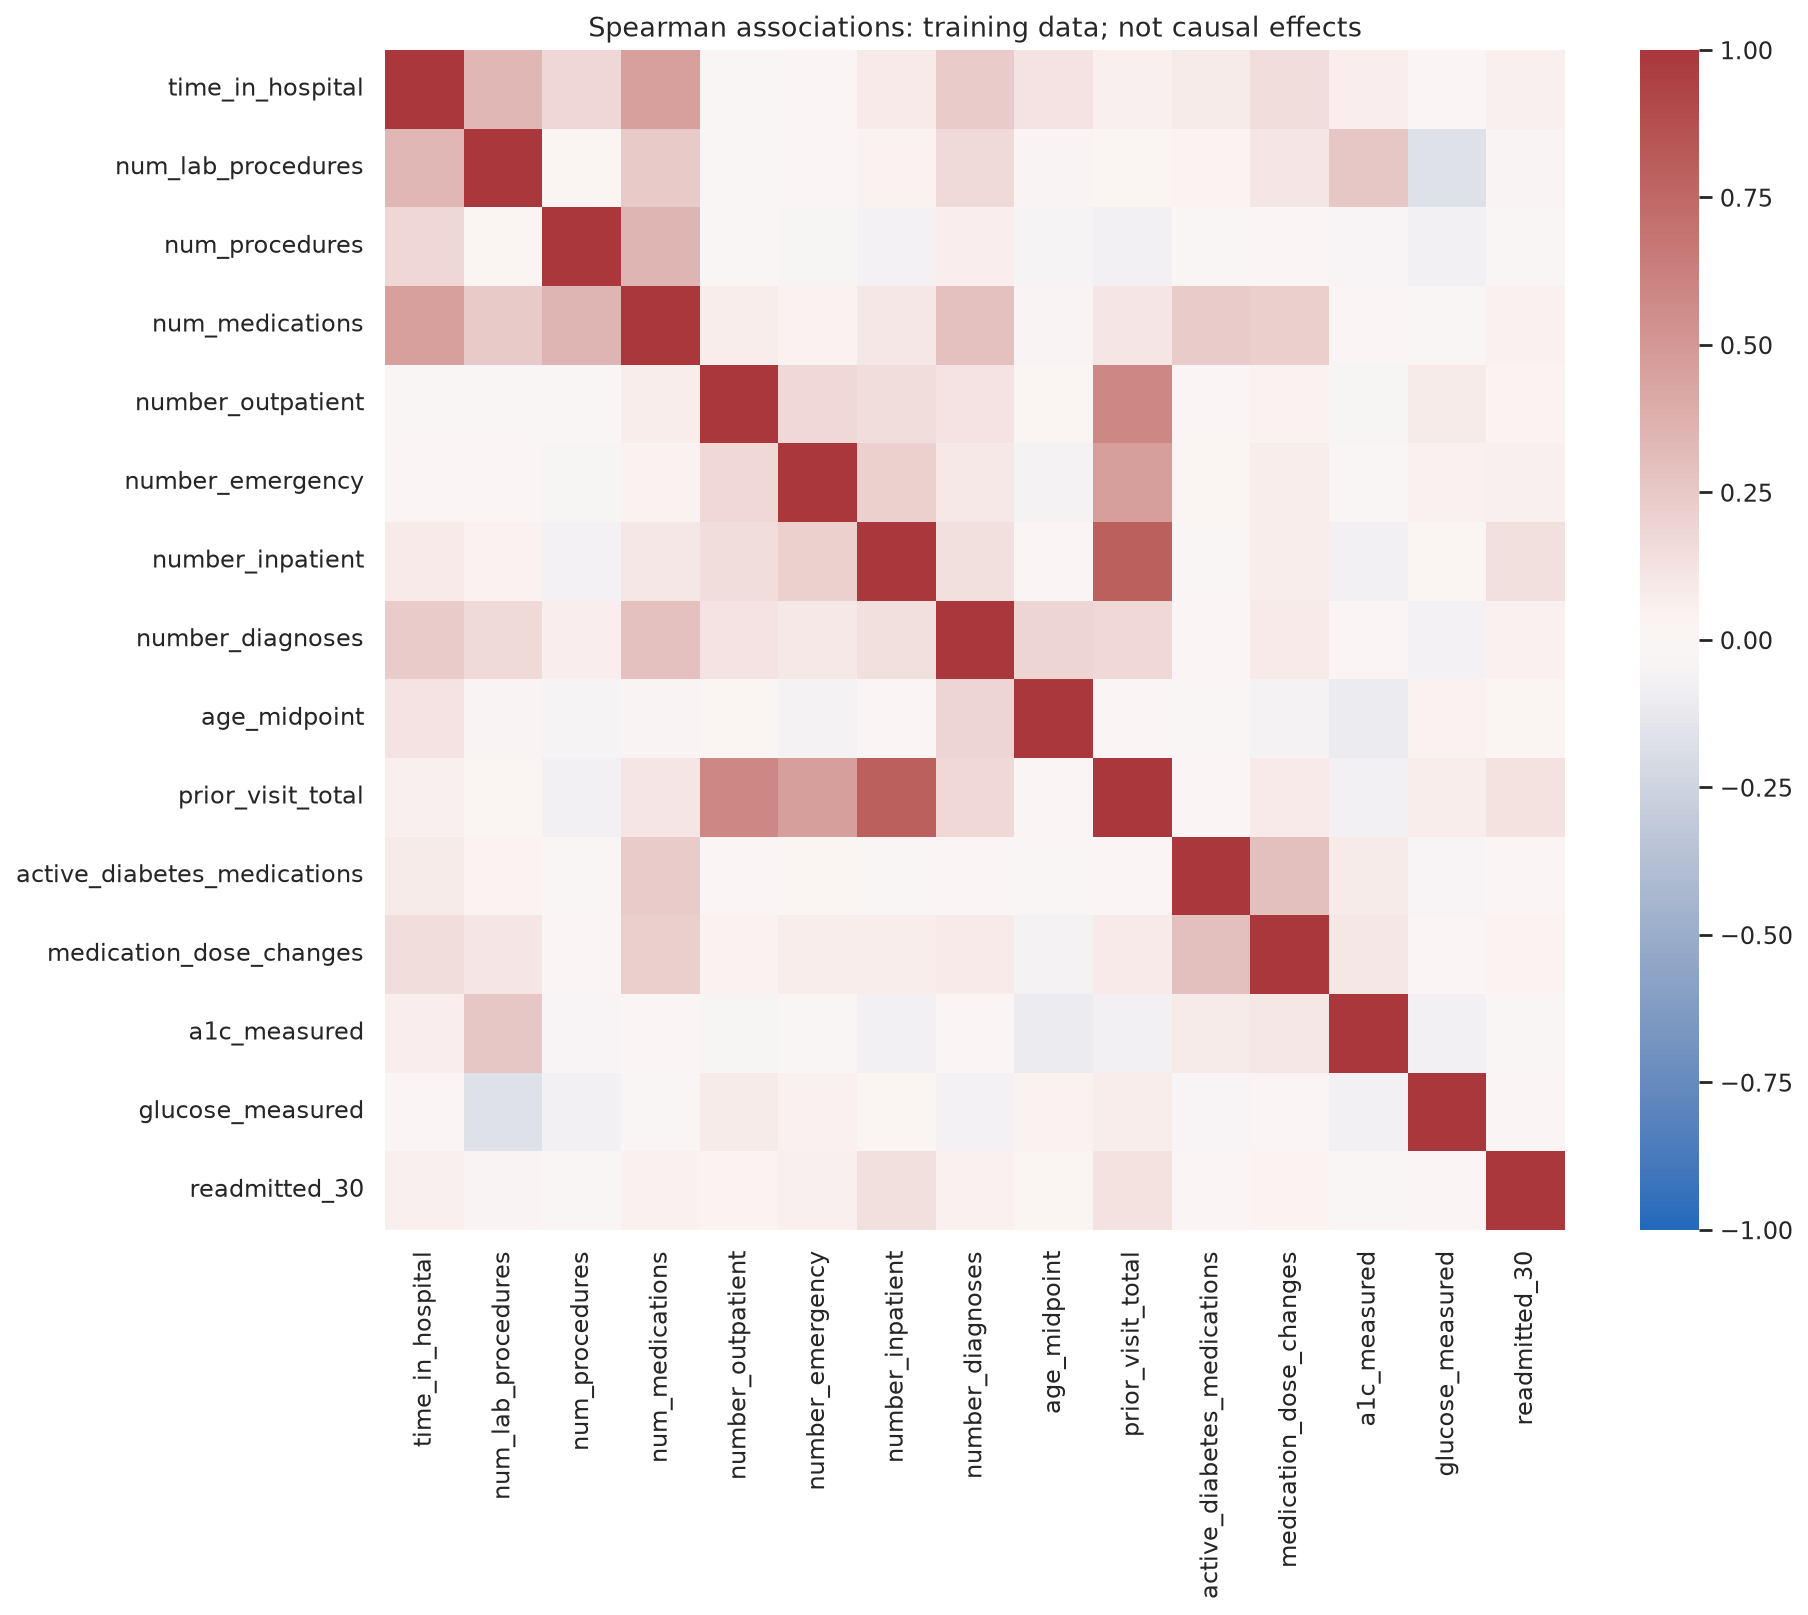

In [6]:
figure("eda_prior_visits.png")
figure("eda_diagnoses.png")
figure("eda_clinical_predictors.png")
figure("eda_numeric_associations.png")

In [7]:
rates = pd.read_csv(ROOT / "reports/training_group_readmission_rates.csv")
display(rates.loc[rates.n >= 100].sort_values("rate", ascending=False).head(15))

,attribute,group,n,positives,rate,lower,upper
39,discharge_disposition_id,28,100,35,0.350000,0.263642,0.447456
34,discharge_disposition_id,22,1284,351,0.273364,0.249690,0.298391
64,number_inpatient_band,3+,4226,1109,0.262423,0.249379,0.275899
72,number_emergency_band,3+,1017,258,0.253687,0.227906,0.281322
42,discharge_disposition_id,5,751,161,0.214381,0.186522,0.245147
63,number_inpatient_band,2,4671,847,0.181332,0.170546,0.192641
71,number_emergency_band,2,1238,220,0.177706,0.157419,0.199987
84,diag_1_group,Supplementary V code,1031,168,0.162949,0.141663,0.186736
33,discharge_disposition_id,2,1364,222,0.162757,0.144118,0.183289
44,discharge_disposition_id,7,396,62,0.156566,0.124094,0.195636


## Consequences for modelling
Use training-fitted missingness removal, imputation and infrequent-category encoding; scale numbers for logistic regression. Compare against a prior-only baseline. Keep every patient's encounters in one split. Exclude identifiers and the outcome; omit race, gender and payer from the primary feature set while retaining demographics for audit. Exclusion alone does not ensure fairness. The EDA informs interpretation, not a post hoc test-driven model search.